<style>
/* Компактные таблицы */
table td, table th,
div.rendered_html table td, div.rendered_html table th,
.jp-RenderedHTMLCommon table td, .jp-RenderedHTMLCommon table th,
table.dataframe td, table.dataframe th {
    padding-top: 2px !important;
    padding-bottom: 2px !important;
    line-height: 1.15 !important;
}

/* Компактные заголовки разделов */
h1, h2, h3, h4, h5, h6,
div.rendered_html h1, div.rendered_html h2, div.rendered_html h3,
div.rendered_html h4, div.rendered_html h5, div.rendered_html h6,
.jp-RenderedHTMLCommon h1, .jp-RenderedHTMLCommon h2, .jp-RenderedHTMLCommon h3,
.jp-RenderedHTMLCommon h4, .jp-RenderedHTMLCommon h5, .jp-RenderedHTMLCommon h6 {
    margin-top: 0.4em !important;
    margin-bottom: 0.2em !important;
    padding-top: 0 !important;
    padding-bottom: 0 !important;
    line-height: 1.2 !important;
}

/* Чуть плотнее абзацы и списки после заголовков */
p, ul, ol, blockquote,
div.rendered_html p, .jp-RenderedHTMLCommon p {
    margin-top: 0.3em !important;
    margin-bottom: 0.3em !important;
}
</style>

<style>
/* --- Компактные заголовки разделов --- */
h1, h2, h3, h4, h5, h6,
div.rendered_html h1, div.rendered_html h2, div.rendered_html h3,
div.rendered_html h4, div.rendered_html h5, div.rendered_html h6,
.jp-RenderedHTMLCommon h1, .jp-RenderedHTMLCommon h2, .jp-RenderedHTMLCommon h3,
.jp-RenderedHTMLCommon h4, .jp-RenderedHTMLCommon h5, .jp-RenderedHTMLCommon h6 {
    margin-top: 0.3em !important;
    margin-bottom: 0.15em !important;
    padding-top: 0 !important;
    padding-bottom: 0 !important;
    line-height: 1.2 !important;
}

/* --- Не отрывать заголовок от следующего блока --- */
h1, h2, h3, h4 { break-after: avoid !important; page-break-after: avoid !important; }
h1 + *, h2 + *, h3 + *, h4 + * { break-before: avoid !important; page-break-before: avoid !important; }

/* --- Не разрывать таблицы и графики между страницами --- */
table, figure, img, .output_png, .output_svg, .jp-OutputArea-output {
    break-inside: avoid !important;
    page-break-inside: avoid !important;
}

/* --- Опционально: чуть плотнее сами страницы --- */
@page { margin: 12mm 12mm !important; }
</style>

<style>
h1, h2, h3, h4, h5, h6,
div.rendered_html h1, div.rendered_html h2, div.rendered_html h3,
div.rendered_html h4, div.rendered_html h5, div.rendered_html h6,
.jp-RenderedHTMLCommon h1, .jp-RenderedHTMLCommon h2, .jp-RenderedHTMLCommon h3,
.jp-RenderedHTMLCommon h4, .jp-RenderedHTMLCommon h5, .jp-RenderedHTMLCommon h6 {
    break-after: avoid-page !important;
    page-break-after: avoid !important;
}

h1 + *, h2 + *, h3 + *, h4 + *, h5 + *, h6 + *,
h1 + table, h2 + table, h3 + table, h4 + table, h5 + table, h6 + table {
    break-before: avoid-page !important;
    page-break-before: avoid !important;
}

table, figure, img, .output_png, .output_svg, .jp-OutputArea-output {
    break-inside: avoid-page !important;
    page-break-inside: avoid !important;
}
</style>

# Снижение активности по картам: кто, насколько и за счёт чего

**Автор:** Дмитриченко Пётр **Период данных:** 2024-01-01 — 2025-06-30 **Подготовлено для:** департамент розничных продуктов, банк «Меридиан»

<!--
Этот ноутбук собирается в HTML командой:
jupyter nbconvert --to html --no-input --execute 02_report.ipynb --output report.html

Поэтому: кода читатель не видит, все графики и таблицы получены
исполнением, числа в тексте должны совпадать с выводом кода.
Лимит: 6 страниц и 8 графиков.
-->

## 1. Главное
<!-- 3–5 выводов с числами. Пишется последним, читается первым.
     Каждый вывод — утверждение, а не тема. Не «анализ активности»,
     а «активность упала на X% у группы Y за счёт Z». -->
1. **Медиана активности упала на 3.3 оп/мес у базового сегмента (с 6.3 до 3.1) — на 0.97 оп/мес сильнее, чем у зарплатного,** который упал меньше остальных.
2. **Медиана активности упала на 3.4 оп/мес у клиентов с высоким уровнем активности (с 10.8 до 7.4) — на 1.71 оп/мес сильнее, чем у низкоактивных;** падение произошло в основном за счёт снижения активности активных клиентов, а не ухода мало или среднеактивных.
3. **Число операций по оплате картой упало на 4 244 оп/мес (с 16 902 до 12 658), тогда как токен не менялся;** медиана активности клиентов без приложения падает на 0.84 оп/мес сильнее (с 6.4 до 3.0), чем с приложением.
4. **По числу операций падение сконцентрировано в базовых потребностях:** «Продукты» — на 1 133 оп/мес больше минимального падения (с 8 501 до 7 277), «Одежда и обувь» — на 883 больше минимального (с 3 602 до 2 628); медиана активности сильнее всего упала у базового (с 6.3 до 3.1, −3.2 оп/мес) и серебряного (с 6.7 до 3.7, −3.0 оп/мес) уровней лояльности.

## 2. Контекст

<!-- Какое решение поддерживает этот отчёт, 3–5 предложений. -->

В нашем банке произошло снижение активности клиентов пользующихся продуктом карта.
Снижение произошло неравномерно по разным группам клиентов и типам их основных трат, каналов этих трат.
Были выбраны 3 группы клиентов по их категориям для проведения маркетинговой кампании чтобы восстановить их активность.

## 3. Данные и ограничения

<!-- Период, число клиентов и операций, что и почему исключено из расчёта,
     чего в данных нет.

     Здесь же одним абзацем: какую метрику активности вы выбрали,
     как она считается и какое снижение она не увидит. -->

В распоряжении периоды дат от 2024-01 до 2025-06. Основное снижение активности произошло 2025-01. В исходных данных были 5713 клиентов и 611074 транзакций. После очистки и фильтрации данных осталось 5,658 клиентов и 517,903 транзакций, по причине ошибок в данных и отсутствия связей подробнее в №8.

В данных нет: динамики\истории оценки банка клиентом; информации о транзакциях за пределами периода; информации об других продуктах которыми пользовался клиент(например вклад или кредит); информации о том использует ли клиент продукты других банков и какие; основная метрика не учитывает обьем операций тк цель данной работы активность.

Была выбрана затухающее количество операций клиента как месячная метрика, в тех же единицах и масштабе что и количество операций в месяц но сглажено для подавления шума.
В качестве маркера того что клиент снизил активность и насколько используется 
Дельта = медиана(3 из 4х самых активных месяца, без лучшего для подавления пика предположительно вызванного тратой денег с карты перед отказом или частичным отказом от её использования) - медиана(3 последних месяца)


## 4. Находки

<!-- По одной находке на подраздел. Заголовок подраздела — вывод,
     а не тема. Под заголовком: график или таблица, затем 2–4
     предложения. -->

In [30]:
# ============================================================
# §4 — 6 графиков. Только drop-bar (правая панель из §7.1 / §7.2).
# Источник: clean_clients.parquet + clean_txn.parquet.
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ---- 1. Загрузка ----
feat = pd.read_parquet('clean_clients.parquet').set_index('client_id')

txn = pd.read_parquet('clean_txn.parquet')
txn['txn_datetime'] = pd.to_datetime(txn['txn_datetime'])
txn['month'] = txn['txn_datetime'].dt.to_period('M').dt.to_timestamp()

plot_months = pd.date_range('2024-01-01', '2025-06-01', freq='MS')

txn_ok = txn[(txn['status'] == 'успешно') &
             (txn['currency'] == 'RUB')].copy()

ops = (txn_ok.groupby(['client_id', 'month']).size()
             .unstack(fill_value=0)
             .reindex(columns=plot_months, fill_value=0))

pool_show = feat[feat['delta'].notna() &
                 feat.index.isin(ops.index)].copy()
#print(f'клиентов с посчитанной delta: {len(pool_show):,}\n')


# ============================================================
# Bar-drop по клиентскому срезу — правая панель §7.1
# ============================================================
def bar_client_drop(col, title, chart_no):
    data = pool_show.dropna(subset=[col, 'delta']).copy()
    if len(data) < 30:
        return
    stats = (data.groupby(col, observed=True)
                 .agg(n=('delta', 'size'),
                      before=('before', 'median'),
                      after=('after', 'median'))
                 .reset_index())
    stats['delta'] = stats['after'] - stats['before']
    stats = stats[stats['n'] >= 30].sort_values('delta', ascending=False)
    if len(stats) < 2:
        return

    palette = list(plt.cm.tab20.colors)
    color_map = {val: palette[i % len(palette)]
                 for i, val in enumerate(stats[col])}

    h = max(1.2, 0.28 * len(stats) + 0.5)
    fig, ax = plt.subplots(figsize=(9, h), layout='constrained')
    drops = -stats['delta'].values
    min_drop = drops.min()
    y = np.arange(len(stats))
    ax.barh(y, drops,
            color=[color_map[v] for v in stats[col]],
            edgecolor='black', lw=0.4, alpha=0.85)
    for i, (row, drop) in enumerate(zip(stats.itertuples(), drops)):
        excess = drop - min_drop
        suffix = '  min' if excess < 0.01 else f'  +{excess:.2f} vs min'
        ax.text(drop + 0.02, i,
                f'{row.before:.1f}→{row.after:.1f}  (n={row.n}){suffix}',
                va='center', fontsize=8)
    ax.set_yticks(y)
    ax.set_yticklabels(stats[col].astype(str), fontsize=9)
    ax.axvline(0, color='k', lw=0.8)
    ax.set_xlabel('падение = до − после, оп/мес')
    ax.set_title(f'4.{chart_no} — {title}: падение\n'
                 f'min drop = {min_drop:.2f}, "vs min" = выше базового')
    ax.grid(alpha=0.3, axis='x')
    ax.set_xlim(0, max(drops) * 1.35)
    plt.show()


# ============================================================
# Bar-drop по транзакционному срезу — правая панель §7.2
# ============================================================
def build_txn_stats(df, col):
    tmp = df.groupby(['month', col]).size().unstack(fill_value=0)
    tmp = tmp.reindex(plot_months, fill_value=0)
    rows = []
    for val in tmp.columns:
        s = tmp[val]
        before = float(s.nlargest(4).iloc[1:].median())
        after = float(s.iloc[-3:].median())
        rows.append({'val': val, 'before': before, 'after': after,
                     'delta': after - before})
    df_stats = pd.DataFrame(rows).sort_values('delta', ascending=False)
    min_drop = float((-df_stats['delta']).min())
    return df_stats, min_drop


def bar_txn_drop(df, col, title, chart_no, ylabel_short='шт/мес'):
    df_stats, min_drop = build_txn_stats(df, col)
    if len(df_stats) < 2:
        return

    palette = list(plt.cm.tab20.colors)
    color_map = {val: palette[i % len(palette)]
                 for i, val in enumerate(df_stats['val'])}

    h = max(1.2, 0.28 * len(df_stats) + 0.5)
    fig, ax = plt.subplots(figsize=(9, h), layout='constrained')
    drops = -df_stats['delta'].values
    y = np.arange(len(df_stats))
    ax.barh(y, drops,
            color=[color_map[v] for v in df_stats['val']],
            edgecolor='black', lw=0.4, alpha=0.85)
    for i, (row, drop) in enumerate(zip(df_stats.itertuples(), drops)):
        excess = drop - min_drop
        suffix = '  min' if excess < 1 else f'  +{excess:.0f} vs min'
        ax.text(drop + max(drops) * 0.01, i,
                f'{row.before:.0f}→{row.after:.0f}{suffix}',
                va='center', fontsize=9)
    ax.set_yticks(y)
    ax.set_yticklabels(df_stats['val'].astype(str), fontsize=10)
    ax.axvline(0, color='k', lw=0.8)
    ax.set_xlabel(f'drop = before − after, {ylabel_short}')
    ax.set_title(f'4.{chart_no} — {title}: падение\n'
                 f'min drop = {min_drop:.0f}')
    ax.grid(alpha=0.3, axis='x')
    ax.set_xlim(0, max(drops) * 1.35)
    plt.show()

### 4.1. Падение по сегментам(Медиана дельта клиентов)
Базовый сегмент упал сильнее всего с 6 оп/мес до 2.7 оп/мес что на 1.18 оп/мес больше падения зарплатного сегмента который упал меньше остальных.

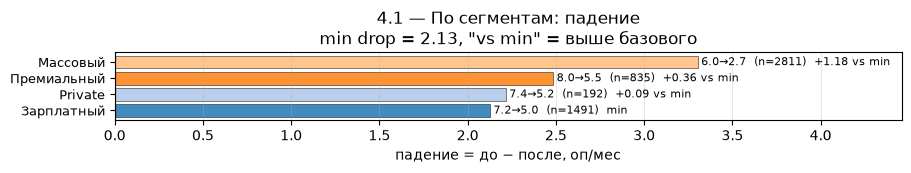

In [31]:
bar_client_drop('segment',        'По сегментам',            1)   # 7.1.1–2

### 4.2 Падение по уровню активности(Медиана дельта клиентов)
По уровню активности упали сильнее клиенты с высоким уровнем с 10.8 оп/мес до 7.4 оп/мес что на 1.71 оп/мес больше падения клиентов с низким уровнем активности, активность которых которые упала меньше остальных. Это говорит о том что падение в основном могло произойти за счёт снижения активности активных клиентов а не ухода мало или среднеактивных.

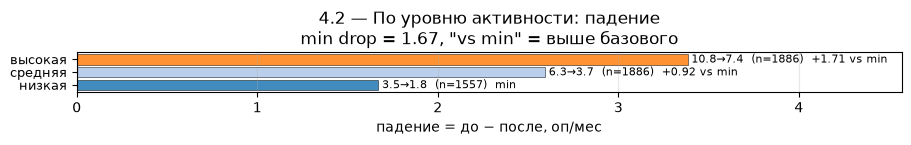

In [32]:
bar_client_drop('activity_level', 'По уровню активности',    2)   # 7.1.17–18

### 4.3 Падение по способу оплаты(Сумма дельта)
Оплата картой упала сильнее всего с 16902 оп/мес до 12658 оп/мес что на 4244 оп/мес больше падения оплатой токеном активность которого не менялась.

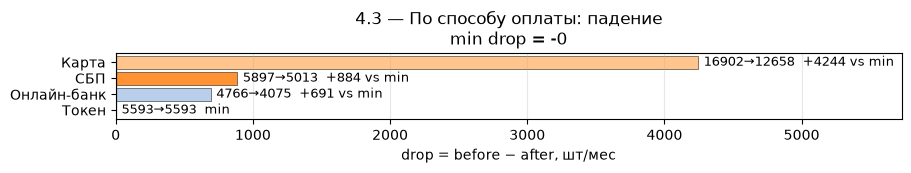

In [33]:
bar_txn_drop   (txn_ok, 'channel','По способу оплаты',       3)   # 7.2.3–4

### 4.4 Падение по наличию приложения(Медиана дельта клиентов)
Активность клиентов без приложения упала сильнее с 6.4 оп/мес до 3 оп/мес что на 0.84 оп/мес больше падения активности клиентов которые пользуются приложением.

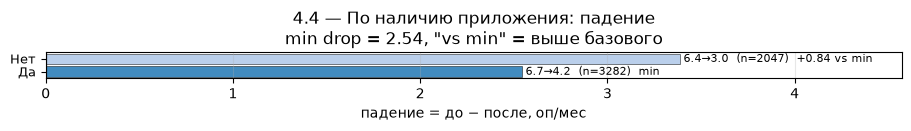

In [34]:
bar_client_drop('has_mobile_app', 'По наличию приложения',   4)   # 7.1.7–8

### 4.5 Падение по категориям трат(Сумма дельта)
Траты на продукты (с 8501 оп/мес до 7277 что на 1133 больше минимального падения кафе и ресторанов) и одежду и обувь(с 3602 оп/мес до 2628 что на 883 больше минимального) упали сильнее всего.
Что говорит о том что падение произошло за счёт клиентов которые которые использовали продукты банка для удовлетворения базовых потребностей.

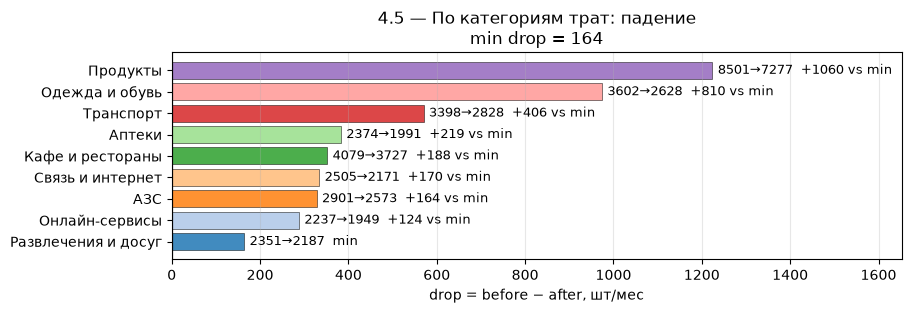

In [35]:
bar_txn_drop   (txn_ok, 'category','По категориям трат',     5)   # 7.2.1–2

### 4.6 Падение по уровню лояльности(Медиана дельта клиентов)
По уровню лояльности больше всего упали базовый(с 6.3 оп/мес до 3.1 оп/мес на 0.97 больше золотого(мин)) и серебрянный(с 6.7 оп/мес до 3.7 оп/мес на 0.97 больше золотого) сегменты.
Это согласуется с гипотезой, что падение сосредоточено у клиентов, использовавших продукты банка для базовых повседневных трат, — тот же паттерн, что в предыдущем пункте; проверка причины требует отдельного разбора, который выходит за рамки данной работы.

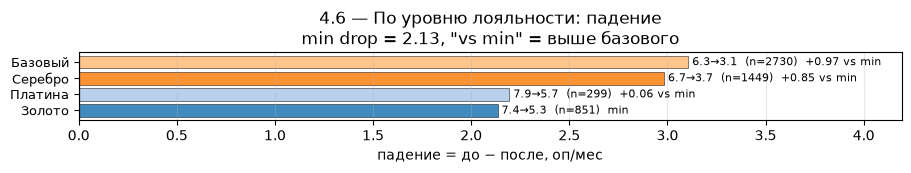

In [36]:
bar_client_drop('loyalty_tier',   'По уровню лояльности',    6)   # 7.1.3–4

<br><br/><br/>
<style>
.jp-RenderedMarkdown table td, .jp-RenderedMarkdown table th,
div.rendered_html table td, div.rendered_html table th,
table td, table th {
    padding: 1px 6px !important;
    line-height: 1.1 !important;
    font-size: 11px !important;
}
</style>

## 5. Группы для кампании

<!-- Таблица: группа, правило отбора, размер, причина падения.
     Ниже — по абзацу на группу. -->

| Группа | Правило отбора | Размер (в группе / в кампанию) | Причина падения |
|---|---|---:|---|
| G1 | высокая активность (`ops_base ≥ 6.89`) · просел канал «Карта» | 817 / 666 | перестали пользоваться картой в повседневных\частых тратах |
| G2 | без приложения · просели траты в «Одежде и обуви» | 697 / 553 | падение трат в «Одежде и обуви» |
| G3 | массовый сегмент + базовый уровень · просели «Продукты» | 367 / 319 | падение трат в «Продуктах» |
| **Итого** | — | **1 881 / 1 538** | — |

**G1 — высокая активность, просел канал «Карта» (817 в группе, 666 в кампанию, медиана Δ −4.18 ops/мес).** Самое глубокое падение в выборке: в 1.7 раза сильнее медианы пула (−2.49 ops/мес).

**G2 — без приложения, просели траты в «Одежде и обуви» (697 / 553, медиана Δ −3.00 ops/мес).** Падение в 1.2 раза сильнее медианы пула.

**G3 — массовый сегмент + базовый уровень, просели «Продукты» (367 / 319, медиана Δ −3.25 ops/мес).** Падение в 1.3 раза сильнее медианы пула.

## 6. Кого не включаем и почему

<!-- Отдельным списком. Для каждой категории: кто это, сколько их,
     почему кампания им не нужна или бесполезна. -->

- **Нет согласия на коммуникацию — 700 клиентов (12.4%).** Кампания невозможна по юридическим и этическим причинам: без согласия нельзя направлять коммуникацию, поэтому такие клиенты исключены независимо от потенциала.
- **Нет базы для оценки (`ops_base = 0`) — 334 клиента (5.9%).** Нельзя корректно оценить динамику активности и потенциал: отсутствует база для расчёта падения, поэтому отбор в целевую группу был бы необоснованным.
- **История < 7 месяцев с картой — 0 клиентов (0.0%).** В текущей выборке таких клиентов нет; правило исключения сохраняется на будущее, так как короткая история не позволяет надёжно отделить падение от естественной нестабильности.
- **Не падали (`delta ≥ 0`) — 514 клиентов (9.1%).** У этих клиентов нет падения активности, поэтому кампания удержания/реактивации им не нужна: коммуникация была бы нерелевантной и снижала бы доверие.
- **Падали, но не попали ни в одну группу — 2 572 клиента (45.5%).** Падение есть, но клиенты не соответствуют критериям выбранных целевых групп; массовая кампания по ним была бы недостаточно персонализированной и менее эффективной. Для них нужен отдельный анализ и, возможно, иной сценарий коммуникации.
- **Итого исключено — 4 120 клиентов (72.8%).**

В кампании остаётся 1 538 клиентов (27.2%) из 5 658.

Все проценты от 5 658.

## 7. Что проверили и что не подтвердилось

<!-- 3–5 строк, по одной на гипотезу, каждая с числом. -->
**Порог эффекта.** За «эффект, ради которого стоит выделять отдельную группу» принята треть медианного падения по пулу: `EFFECT_THRESHOLD = |−2.11| / 3 = 0.70 ops/мес`. Обоснование: пул в среднем теряет 2.11 ops/мес — если различие между подгруппами меньше трети этой величины, оно тонет в общем тренде и не даёт практического основания для отдельной кампании; эффект порядка 0.3–0.5 ops/мес статистически ловим на больших n, но операционно неотличим от шума. Для категориальных сравнений использован Kruskal–Wallis (не Spearman: пол/тип карты/город/возраст — номинальные), решение «A» требует одновременно `|эффект| ≥ 0.70` **и** `p < 0.05`. Исключение — H10: она меряется в п.п. доли отказов, поэтому у неё своя шкала `H10_THRESHOLD = 2.0 п.п.` (2 п.п. — заметный сдвиг процесса одобрения, порог 0.70 ops/мес к ней неприменим).

Не прошли порог или p:

- **H1 — наличие приложения:** медиана delta «с приложением» vs «без» = −1.90 vs −2.50, разница +0.59 ops/мес < 0.70 (KW p<0.0001 — значимо, но не признак сам по себе);
- **H4 — возраст (`age_bucket`):** разброс медиан 0.42 ops/мес (25-35: −1.66, 35-45: −2.06, …) < 0.70; не подтверждена.
- **H5 — оценка сервиса (1–5):** разброс медиан 0.66 ops/мес, диапазон [−2.36; −1.70], KW p=0.0120 — значимо, но 0.66 < 0.70; не подтверждена.
- **H6 — пол:** разница медиан (М − Ж) = −0.03 ops/мес (М −2.12, Ж −2.09), KW p=0.8346; не подтверждена.
- **H7 — тип карты:** разброс медиан 0.50 ops/мес (Дебетовая −2.15, Кредитная −2.11, …) < 0.70; не подтверждена.
- **H8 — город (`city_top`):** разброс медиан 0.35 ops/мес, диапазон [−2.33; −1.98], KW p=0.0518 — и эффект ниже порога, и p на границе; не подтверждена.
- **H9 — уровень дохода (`income_bucket`):** разброс медиан 0.46 ops/мес (низкий −2.27, ниже среднего −2.15, …) < 0.70; не подтверждена.
- **H10 — рост доли отказов:** сдвиг доли отклонённых 2024→2025 = −0.08 п.п. (2.00% → 1.92%) < 2.0 п.п. — доля отказов стабильна, падение не объясняется ужесточением банка; не подтверждена.

## 8. Приложение

### 8.1. Сводка журнала изменений

Полный журнал — в `cleaning_log.csv`. Ниже — сводка по типам нарушений (11 строк).

| Поле | Что найдено | Файл | Строк | Что сделано |
|---|---|---|---:|---|
| `client_id` | дубли ключа справочника | `clients.csv` | 55 | удалено: 5713 → 5658 строк |
| `birth_date` | нераспознанная дата (смешанные форматы) | `clients.csv` | 3437 | приведено к `datetime`, нераспознанные → `NaT` |
| `monthly_income` | единицы измерения: значения в тыс. руб. | `clients.csv` | 247 | умножено на 1000 (напр. 57.6 → 57 600 ₽) |
| `city` | разнобой написания (регистр, «г./гор.», пробелы, ё/е) | `clients.csv` | 1953 | нормализовано: 17 → 9 вариантов |
| `category` | разнобой написания (регистр, слэш вместо «и», пробелы) | `transactions.csv` | 50 898 | нормализовано: 12 → 9 вариантов |
| `monthly_income` | пропуски | `clients.csv` | 574 | оставлено `NaN` |
| `satisfaction_score` | пропуски | `clients.csv` | 3367 | оставлено `NaN` |
| `app_last_login` | пропуски | `clients.csv` | 2157 | оставлено `NaT` |
| `amount` | выбросы: суммы выше 3·IQR (> 7613.76) | `transactions.csv` | 21531 | без изменений |
| `status` | в расчёте активности только успешные операции | `transactions.csv` | 19271 | отклонено/возврат исключены, оставлено только «успешно» |
| `currency` | оставлены только рублёвые операции | `transactions.csv` | 2389 | иные валюты исключены, оставлено только RUB |

### 8.2. Методика

<!-- Точные формулы, фильтры, пороги и их значения. Всё, что нужно,
     чтобы повторить расчёт. -->

**Метрика `ops_c(τ)`** — затухающее нормированное число операций:
ops_c(τ) =  Σ_{i: 0 ≤ τ − t_i < 6}  0.5^((τ − t_i)/HL)/Σ_{k=0}^{K_c(τ)}  0.5^(k/HL)

K_c(τ) = min(5, T_c(τ) − 1),
T_c(τ) — число месяцев от card_open_date клиента c до τ включительно
- `t_i` — номер месяца i-й операции клиента.
- **`HL = например 1` месяц** — период полураспада: операция в текущем месяце (`τ − t_i = 0`) весит 1.0, месяц назад (`τ − t_i = 1`) — 0.5, три месяца назад — `0.5^3 = 0.125`, шесть месяцев назад — `0.5^6 ≈ 0.016`. Значение `HL` подбирается по данным, здесь — иллюстрация формулы с `HL = 1`.
- Знаменатель — сумма весов полного окна (`≈ 1.97` при `HL = 1`), 
поэтому для клиента с одинаковым числом операций в каждом месяце окна `ops_c(τ)` равно этому числу (1:1 с `ops_raw` в стабильном случае).
- Для клиента, у которого окно усечено (`registration_date` < 6 месяцев назад), вес нормируется на фактически накопленный, а не на полный.
**Единица — операций в месяц.** Метрика линейна и номинальна: складывается по клиентам, медиана, среднее и разность определены.
**Сравнение с фактом** — обычное число операций за календарный месяц `ops_raw_c(τ) = count операций в месяце τ`. 
Те же единицы, тот же масштаб. Расхождение = эффект затухания и окна.

Период полураспада метрики: 0.6518 выбран для компенсации шума медианного по шуму клиента. 
CV = std / mean 
R выбран путем перебора или эмпирически в диапазоне R_HIGH, R_LOW = 0.65, 0.15 
с ограничением периода полураспада(HALF_LIFE_MONTHS, HL) до 1.1, при этом задержка(lag) ограничена 1 месяц.
HALF_LIFE_MONTHS = 0.6518
  R(HL) = 0.4883
  lag   = 0.517 мес

Затухающее нормированное число операций коррелирует по Пирсон поперечная корреляция по месяцам сильнее всего с числом операций за этот же месяц из группы от -3 до +3 месяца.
Это говорит о том что выбранная метрика не создает задержки больше одного месяца а значит может отображаться на графиках за месяц её расчета.
подробнее в 01_analysis.ipynb №6.3.

**Дельта** = медиана(3 из 4х самых активных месяца, без лучшего для подавления пика предположительно вызванного тратой денег с карты перед отказом или частичным отказом от ей использования(**ops_base**)) - медиана(3 последних месяца)
**Дельта от минимального падения в группе** = дельта - минимальная дельта в группе
(например зарплатный сегмент дельта 2.2(минимум в группе сегментов) а массовый дельта 3.3, 
соответственно Дельта от минимального падения в группе для массового = 1.2, для зарплатного 0)

### 8.3. Использование ИИ

<!-- 3–5 строк: для чего использовали и что проверили сами. -->
Использован DeepSeek-V4-Pro MoE 1.6T A49B: генерация кода ячеек, сверка с ТЗ, поиск ошибок, проверка орфографии и логики.
Самостоятельно проверены работоспособность кода и сгенерированные артефакты, используемые метрики.
Производительность и оптимальность алгоритмов не проверялись: ноутбуки выполняются до 5 минут на современном ноутбуке, что приемлемо.
